# 04 · Priors y configuración

**Objetivo:** aprender a describir *qué* señales quieres:

- construir configuraciones como diccionarios de Python;
- ver qué distribuciones de 𝓜, M_tot, q, χ_eff, SNR y distancia producen los distintos priors;
- fijar parámetros desde un CSV;
- usar los modos `snr` y `distance`;
- interpretar los avisos de validez.

**Requisitos:** tutoriales 01 a 03. Las claves de configuración están en `docs/CONFIGURACION.md`.

**Tiempo aproximado:** 1–2 minutos (el muestreo de priors es instantáneo; se generan 6 señales).

In [1]:
import sys, warnings, json, copy
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == 'tutorials':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

PSD_PACK = 'psd_pack_o3b.npz'
pack_path = Path(PSD_PACK) if Path(PSD_PACK).is_absolute() else ROOT / PSD_PACK
USE_PACK = pack_path.is_file()
if not USE_PACK:
    warnings.warn(f'No encuentro {pack_path}: uso ruido analítico (curvas de diseño), no las PSD de O3b.')

from gwsim.noise import PsdPackNoise, AnalyticNoise
O3B_GPS = [1256655618.0, 1269363618.0]
noise = PsdPackNoise(pack_path, ['train']) if USE_PACK else AnalyticNoise(O3B_GPS)
NOISE_CFG = ({'source': 'psd_pack', 'psd_pack': str(pack_path), 'splits': ['train']} if USE_PACK
             else {'source': 'analytic', 'gps_range': O3B_GPS})
OUT = ROOT / 'tutorials' / 'salidas'
OUT.mkdir(exist_ok=True)
PAIR = ['#0072b2', '#d55e00']   # dos priors comparados en cada figura

/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal


## 1. Configuraciones como diccionarios

Una configuración de gwsim es un JSON, que en Python es un `dict`. `DEFAULT_CONFIG` contiene todos los valores por defecto. Lo habitual es copiarlo y cambiar solo lo necesario, porque las claves que no escribas toman su valor por defecto.

`load_config` lee un JSON, aplica los valores por defecto y **valida**: si algo está mal, lanza un `ConfigError` que dice qué clave falla; si algo es válido pero dudoso, devuelve un aviso. Es la misma validación que hace `python -m gwsim generate`.

In [2]:
from gwsim.config import DEFAULT_CONFIG, load_config, ConfigError
print(json.dumps(DEFAULT_CONFIG['prior'], indent=1))

def validate(cfg_dict, name):
    path = OUT / f'{name}.json'
    path.write_text(json.dumps(cfg_dict, indent=1))
    try:
        cfg, avisos = load_config(path)
    except ConfigError as exc:
        print(f'[{name}] ERROR: {exc}')
        return None
    print(f'[{name}] válida' + ('' if avisos else ', sin avisos'))
    for a in avisos:
        print('   AVISO:', a)
    return cfg

mi_cfg = {'n_samples': 100, 'seed': 1, 'noise': NOISE_CFG,
          'prior': {'masses': {'distribution': 'components_uniform', 'range': [20.0, 60.0]},
                    'spin_1z': {'fixed': 0.0}, 'spin_2z': {'fixed': 0.0}}}
_ = validate(mi_cfg, 'mi_cfg')

/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/waveform/plugin.py:99: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


{
 "masses": {
  "distribution": "components_uniform",
  "range": [
   5.0,
   90.0
  ]
 },
 "spin_1z": {
  "distribution": "uniform",
  "range": [
   -1.0,
   1.0
  ]
 },
 "spin_2z": {
  "distribution": "uniform",
  "range": [
   -1.0,
   1.0
  ]
 },
 "inclination": {
  "distribution": "isotropic"
 },
 "ra": {
  "distribution": "uniform"
 },
 "dec": {
  "distribution": "isotropic"
 },
 "polarization_angle": {
  "distribution": "uniform"
 },
 "target_network_snr": {
  "distribution": "uniform",
  "range": [
   10.0,
   25.0
  ]
 },
 "distance": {
  "distribution": "uniform_volume",
  "range": [
   100.0,
   3000.0
  ]
 }
}
[mi_cfg] válida, sin avisos


## 2. Qué distribuciones produce cada prior de masas

Un prior es la distribución de la que se sortean los parámetros. Lo importante es que **un prior uniforme en unas variables no es uniforme en otras**. Comparamos los dos priors de masas de gwsim:

- `components_uniform`: m₁ y m₂ independientes y uniformes en [5, 90] M☉, después ordenadas (m₁ ≥ m₂). Es el prior por defecto.
- `chirp_mass_q_uniform`: la masa de chirp 𝓜 = (m₁m₂)^(3/5)/M^(1/5) uniforme en [5, 40] M☉ y q = m₂/m₁ uniforme en [0,2; 1].

Usamos directamente las funciones de muestreo de `gwsim.priors`, sin generar formas de onda: 20 000 muestras en milisegundos.

/tmp/ipykernel_320975/2503464599.py:18: UserWarning: Glyph 120028 (\N{MATHEMATICAL BOLD SCRIPT CAPITAL M}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 120028 (\N{MATHEMATICAL BOLD SCRIPT CAPITAL M}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


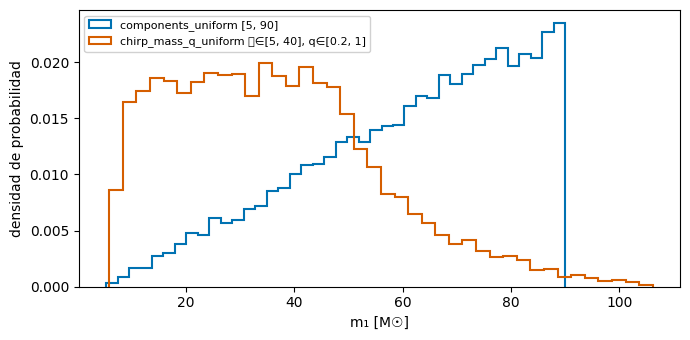

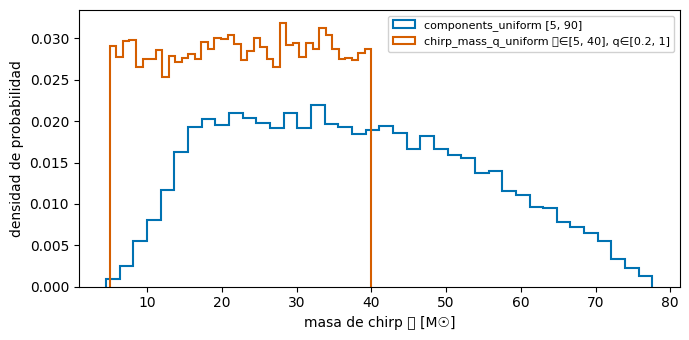

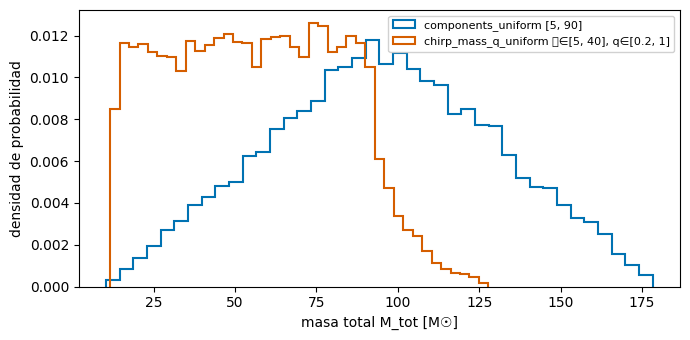

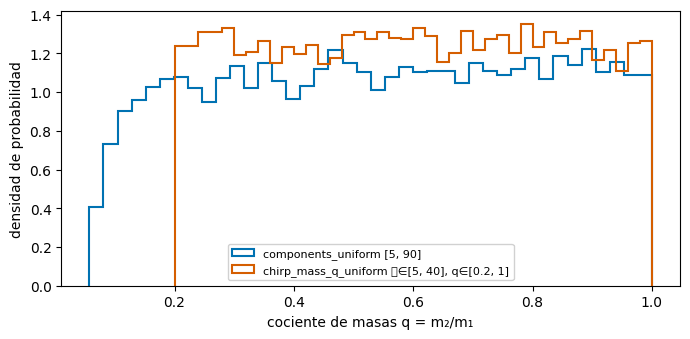

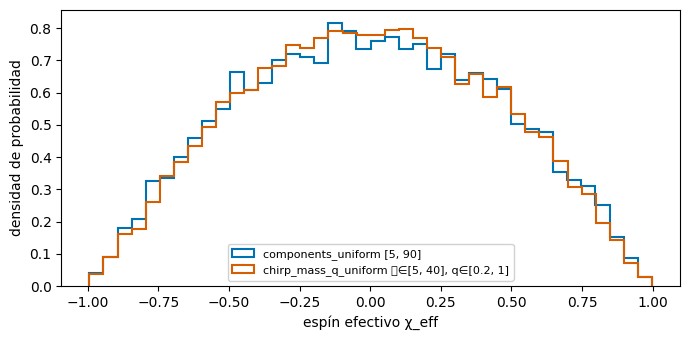

In [3]:
from gwsim.priors import sample_parameters, order_masses, add_derived, sample_amplitude
N = 20000
prior_a = copy.deepcopy(DEFAULT_CONFIG['prior'])
prior_b = copy.deepcopy(DEFAULT_CONFIG['prior'])
prior_b['masses'] = {'distribution': 'chirp_mass_q_uniform', 'chirp_mass_range': [5.0, 40.0], 'q_range': [0.2, 1.0]}
A = add_derived(order_masses(sample_parameters(prior_a, N, np.random.default_rng(0))))
B = add_derived(order_masses(sample_parameters(prior_b, N, np.random.default_rng(0))))
labels = ('components_uniform [5, 90]', 'chirp_mass_q_uniform 𝓜∈[5, 40], q∈[0.2, 1]')

for col, xlabel in [('mass_1', 'm₁ [M☉]'), ('chirp_mass', 'masa de chirp 𝓜 [M☉]'), ('total_mass', 'masa total M_tot [M☉]'),
                    ('q', 'cociente de masas q = m₂/m₁'), ('chi_eff', 'espín efectivo χ_eff')]:
    fig, ax = plt.subplots(figsize=(7, 3.5))
    for df, c, lab in zip((A, B), PAIR, labels):
        ax.hist(df[col], bins=40, density=True, histtype='step', lw=1.5, color=c, label=lab)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('densidad de probabilidad')
    ax.legend(loc='best', framealpha=0.9, fontsize=8)
    plt.tight_layout(); plt.show()

Cómo leer estas figuras:

- Con `components_uniform`, **m₁ no es uniforme**: crece linealmente, porque m₁ = máx(m₁, m₂), y el máximo de dos uniformes tiene densidad triangular.
- M_tot = m₁ + m₂ es triangular, con pico en 95 M☉.
- 𝓜 se acumula en valores intermedios, y q prefiere valores próximos a 1 sin ser uniforme.
- Con `chirp_mass_q_uniform`, 𝓜 y q son planos por construcción, pero M_tot tiene otra forma, con una cola larga para q pequeño.
- χ_eff = (m₁χ₁ + m₂χ₂)/M, con χ₁ y χ₂ uniformes en [−1, 1], es una media ponderada: se concentra en torno a 0 (como la suma de dos uniformes).

Si tu estudio mide algo en función de 𝓜, M_tot o χ_eff, el prior decide **cuántas** señales tienes en cada región. Elígelo pensando en eso.

## 3. SNR y distancia

- En modo `snr`, cada señal tiene una SNR objetivo. `uniform` en [10, 25) pone tantas señales entre 10 y 11 como entre 24 y 25; `loguniform` pone más señales débiles: la misma cantidad en cada factor multiplicativo (8–16 y 15–30).
- En modo `distance`, `uniform_volume` (p(d) ∝ d²) es lo esperable para fuentes repartidas uniformemente en un volumen euclídeo: hay más volumen lejos que cerca. Como ρ ∝ 1/d, la mayoría de las señales salen débiles.

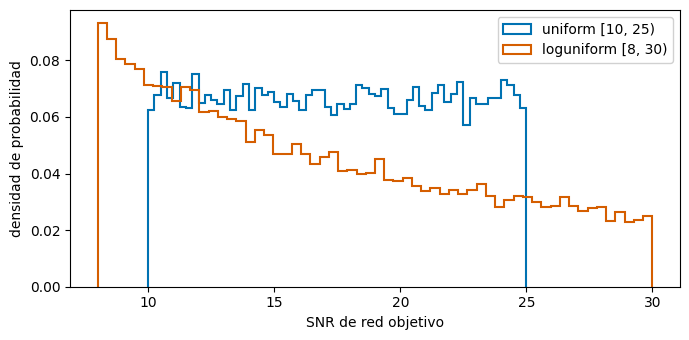

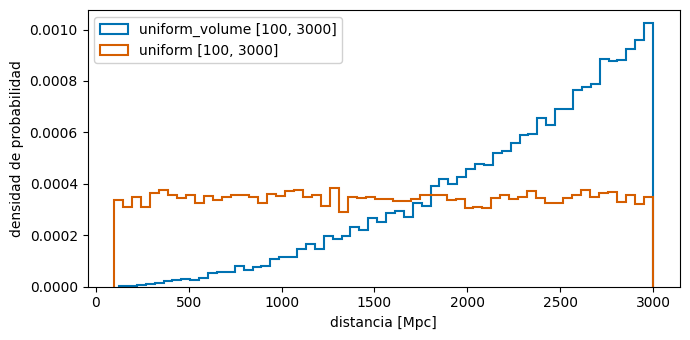

In [4]:
rng = np.random.default_rng(1)
snr_u = sample_amplitude({'distribution': 'uniform', 'range': [10.0, 25.0]}, N, rng, 'SNR')
snr_l = sample_amplitude({'distribution': 'loguniform', 'range': [8.0, 30.0]}, N, rng, 'SNR')
d_v = sample_amplitude({'distribution': 'uniform_volume', 'range': [100.0, 3000.0]}, N, rng, 'distance')
d_u = sample_amplitude({'distribution': 'uniform', 'range': [100.0, 3000.0]}, N, rng, 'distance')

for (va, la), (vb, lb), xlabel in [((snr_u, 'uniform [10, 25)'), (snr_l, 'loguniform [8, 30)'), 'SNR de red objetivo'),
                                   ((d_v, 'uniform_volume [100, 3000]'), (d_u, 'uniform [100, 3000]'), 'distancia [Mpc]')]:
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.hist(va, bins=60, density=True, histtype='step', lw=1.5, color=PAIR[0], label=la)
    ax.hist(vb, bins=60, density=True, histtype='step', lw=1.5, color=PAIR[1], label=lb)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('densidad de probabilidad')
    ax.legend(loc='best', framealpha=0.9)
    plt.tight_layout(); plt.show()

## 4. Parámetros desde un CSV

Si quieres fuentes concretas (una rejilla de masas, un catálogo, las mismas fuentes en dos estudios…), escríbelas en un CSV con una fila por señal. Columnas obligatorias: `mass_1`, `mass_2`, `spin_1z`, `spin_2z`, `inclination`, `ra`, `dec` y `polarization_angle`, más `target_network_snr` (modo `snr`) o `distance` (modo `distance`). Opcionalmente, `placement_seed`, `gaussian_seed` y `noise_crop_id` (o `gps` con ruido analítico).

El CSV sustituye al prior: `n_samples` se ignora.

In [5]:
import pandas as pd
csv = OUT / 'mis_parametros.csv'
pd.DataFrame({
    'mass_1': [30.0, 30.0, 30.0], 'mass_2': [20.0, 20.0, 20.0],
    'spin_1z': [0.0, 0.0, 0.0], 'spin_2z': [0.0, 0.0, 0.0],
    'inclination': [0.0, 0.0, 0.0], 'ra': [1.0, 1.0, 1.0], 'dec': [0.2, 0.2, 0.2],
    'polarization_angle': [0.3, 0.3, 0.3],
    'target_network_snr': [10.0, 15.0, 20.0],      # la misma fuente a tres SNR
}).to_csv(csv, index=False)
print(csv.read_text())

cfg_csv = {'seed': 3, 'noise': NOISE_CFG, 'parameters_file': str(csv), 'outputs': ['X', 'X_noise']}
if validate(cfg_csv, 'desde_csv') is not None:
    out_csv = OUT / '03_desde_csv.h5'
    if out_csv.exists():
        out_csv.unlink()
    cfg_path = OUT / 'desde_csv.json'
    !cd {ROOT} && python -m gwsim generate --config {cfg_path} --output {out_csv}

mass_1,mass_2,spin_1z,spin_2z,inclination,ra,dec,polarization_angle,target_network_snr
30.0,20.0,0.0,0.0,0.0,1.0,0.2,0.3,10.0
30.0,20.0,0.0,0.0,0.0,1.0,0.2,0.3,15.0
30.0,20.0,0.0,0.0,0.0,1.0,0.2,0.3,20.0

[desde_csv] válida
   AVISO: parameters_file: se ignoran n_samples y el prior; una fila por señal
/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/waveform/plugin.py:99: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
AVISO: parameters_file: se ignoran n_samples y el prior; una fila por señal
Creado /afs/ciemat.es/user/v/vserrano/Desktop/gw/gwsim/tutorials/salidas/03_desde_csv.h5: 3 filas
3 filas pendientes de 3; 1 proceso(s)
1/3 (hechas 1, fallidas 0); 3 s
2/3 (hechas 2, fallidas 0); 4 s
3/3 (hechas 3, fallidas 0); 4 s
Terminado: /

In [6]:
import gwsim
d = gwsim.load(OUT / '03_desde_csv.h5', outputs=())
for i in range(len(d['row_index'])):
    print(f'objetivo {d["target_network_snr"][i]:5.1f} -> SNR final {d["final_network_snr"][i]:6.3f}, '
          f'distancia {d["final_distance"][i]:6.0f} Mpc')

objetivo  10.0 -> SNR final 10.000, distancia   1700 Mpc
objetivo  15.0 -> SNR final 15.000, distancia   1101 Mpc
objetivo  20.0 -> SNR final 20.000, distancia   1157 Mpc


La distancia escala como 1/SNR: la fuente con SNR 20 está a la mitad de distancia que la de SNR 10.

## 5. Modo `snr` frente a modo `distance`

- `snr`: tú fijas la SNR y gwsim calcula la distancia. Es lo habitual para estudiar la detectabilidad en función de la SNR, porque controla directamente lo «visible» que es cada señal.
- `distance`: tú fijas la distancia física y la SNR es la que resulte. Depende de las masas, de la orientación, de la posición en el cielo y de la PSD del momento. Es lo natural si quieres poblaciones astrofísicas.

Con la misma fuente, el mismo ruido y tres distancias, la SNR debe ir como 1/d.

d [Mpc]: [ 500. 1000. 2000.]  SNR: [19.303  9.651  4.826]  SNR·d: [9651.5 9651.5 9651.5]


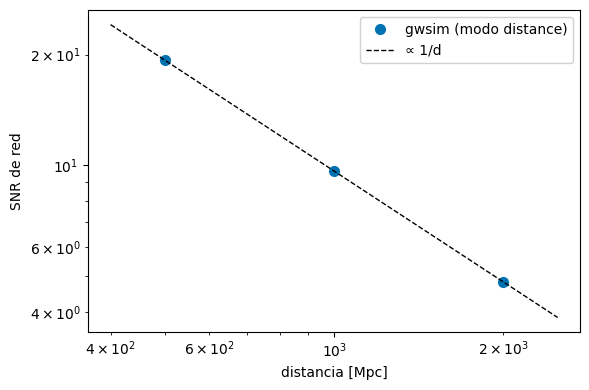

In [7]:
from gwsim.recipe import Physics, RowOptions, simulate_row
phys = Physics()
params = dict(mass_1=30.0, mass_2=20.0, spin_1z=0.0, spin_2z=0.0, inclination=0.0, ra=1.0, dec=0.2,
              polarization_angle=0.3)
a = noise.assign(1, np.random.default_rng(4))
psds = noise.psds(a['block_id'][0], phys.config)
dists = np.array([500.0, 1000.0, 2000.0])
snrs = []
for dist in dists:
    _, m = simulate_row(params, a['gps'][0], psds, 1, 2, distance=dist,
                        opts=RowOptions(physics=phys, mode='distance', outputs=('X',)))
    snrs.append(m['final_network_snr'])
snrs = np.array(snrs)
print('d [Mpc]:', dists, ' SNR:', snrs.round(3), ' SNR·d:', (snrs * dists).round(1))

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(dists, snrs, 'o', color=PAIR[0], ms=7, label='gwsim (modo distance)')
dd = np.geomspace(400, 2500, 50)
ax.loglog(dd, snrs[1] * 1000.0 / dd, color='k', ls='--', lw=1, label='∝ 1/d')
ax.set_xlabel('distancia [Mpc]')
ax.set_ylabel('SNR de red')
ax.legend(loc='upper right', framealpha=0.9)
plt.tight_layout(); plt.show()

SNR·d es el mismo número para las tres distancias.

## 6. Avisos de validez

gwsim distingue dos casos:

- **Errores:** la configuración no tiene sentido o no está soportada, y no se genera nada.
- **Avisos:** la configuración es válida, pero sale de la región validada (`docs/VALIDEZ.md`). Se genera igual, y los avisos quedan guardados en el HDF5.

Probamos tres casos.

In [8]:
# (a) Masas muy pequeñas y muy grandes: tres avisos distintos.
_ = validate({'noise': NOISE_CFG, 'prior': {'masses': {'distribution': 'components_uniform', 'range': [3.0, 150.0]}}},
             'masas_extremas')
# (b) Procesado distinto del validado (filtro de blanqueado de 8 s): aviso.
_ = validate({'noise': NOISE_CFG, 'signal_processor': {'whitening_max_filter_duration': 8.0}}, 'otro_blanqueado')
# (c) Aproximante con precesión: error (gwsim solo tiene espines alineados).
_ = validate({'noise': NOISE_CFG, 'simulation': {'waveform_approximant': 'IMRPhenomXPHM'}}, 'precesion')
# (d) Un rango al revés: error con el nombre de la clave.
_ = validate({'noise': NOISE_CFG, 'prior': {'masses': {'distribution': 'components_uniform', 'range': [60.0, 20.0]}}},
             'rango_al_reves')

[masas_extremas] válida
   AVISO: M_tot puede llegar a 300.0 > 250: región sin validar
   AVISO: M_tot puede superar 180: se usa la banda de arranque alta (10→14 Hz), validada a nivel de forma de onda hasta M_tot = 250; equivalencia con la producción no comprobada en esta región
   AVISO: M_tot puede bajar a 6.0 < 16: algunas formas de onda pueden no generarse (esas filas quedarán con status = 2)
[otro_blanqueado] válida
   AVISO: signal_processor: ['whitening_max_filter_duration'] distintos de la configuración por defecto; esa física no está validada
   AVISO: M_tot puede bajar a 10.0 < 16: algunas formas de onda pueden no generarse (esas filas quedarán con status = 2)
[precesion] ERROR: IMRPhenomXPHM tiene precesión; gwsim solo admite espines alineados
[rango_al_reves] ERROR: prior.masses.range debe estar ordenado [mín, máx]; recibido [60.0, 20.0]


Los avisos de masas significan:

- M_tot < 16 M☉: algunas formas de onda pueden no generarse (esas filas quedarían con `status = 2`);
- M_tot > 180 M☉: se usa la banda de arranque alta (10→14 Hz), validada a nivel de forma de onda hasta 250 M☉; la equivalencia con la producción no está comprobada en esa región;
- M_tot > 250 M☉: región sin validar.

**Siguiente:** `05_conjuntos_pareados_y_rangos.ipynb`.